# **Exercise 7 - Text Clustering**

"*Try applying all clustering methods on the text you have feature engineering from the previous exercise and analyze the given results.*"

Data: review MyTelkomsel hasil preprocessing (review_mytelkomsel_bersih.csv)

*   nadhila alya azzahra (051)
*   gloria jesika oktoniar pardosi (148)

## **Load Data & Feature Engineering**

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from sklearn.feature_extraction.text import TfidfVectorizer

df = pd.read_csv('review_mytelkomsel_bersih.csv')
print("Sebelum dropna :", df.shape)

# review yg isinya kosong setelah preprocessing (mis. cuma emoji) dibuang (sama seperti Exercise 5)
df = df.dropna(subset=['Teks_Bersih'])
df = df[df['Teks_Bersih'].str.strip() != ''].reset_index(drop=True)
print("Setelah dropna :", df.shape)

df_pre = df['Teks_Bersih']

vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(df_pre)
df_FE = pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out())

print("Ukuran data TF-IDF:", df_FE.shape)

Sebelum dropna : (2000, 5)
Setelah dropna : (1886, 5)
Ukuran data TF-IDF: (1886, 1356)


Pada tahap ini, data ulasan MyTelkomsel yang telah melalui preprocessing diubah menjadi representasi numerik menggunakan TF-IDF. Data yang memiliki teks kosong dihapus sehingga diperoleh 1.886 ulasan dari 2.000 data awal. Hasil transformasi TF-IDF menghasilkan matriks berukuran 1.886 × 1.356 yang digunakan sebagai input pada proses clustering.

# **K-Means Clustering**


**menentukan jumlah cluster (k) dengan Elbow Method**

mencoba beberapa jumlah cluster (k=2 sampai k=10) utk mengetahui jumlah cluster yg paling sesuai berdasarkan nilai inertia

In [31]:
from sklearn.cluster import KMeans

k = range(2, 11)
inertia = []

for i in k:
    km_model = KMeans(n_clusters=i, random_state=10)  # jumlah cluster akan di looping
    km_model.fit(df_FE)
    inertia.append(km_model.inertia_)

print(list(k))
print(inertia)

[2, 3, 4, 5, 6, 7, 8, 9, 10]
[1797.5310017565696, 1786.8249168631173, 1736.959168935918, 1707.4476096384433, 1703.7230176101396, 1684.1441086655177, 1686.5758311821573, 1643.6756570302834, 1634.7120720004607]


**visualisasinya:**

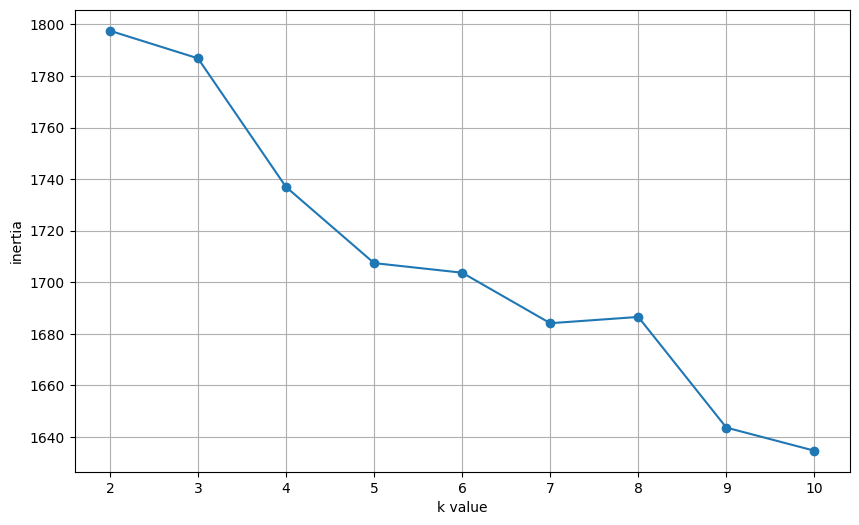

In [32]:
plt.figure(figsize=(10, 6))
plt.plot(k, inertia, marker='o')
plt.xlabel('k value')
plt.ylabel('inertia')
plt.grid()
plt.show()

**Silhouette Score untuk beberapa nilai k** -> supaya pemilihan k tdk cuma mengandalkan elbow yang kadang kurang jelas

In [33]:
from sklearn import metrics

for i in range(2, 11):
    km_model = KMeans(n_clusters=i, random_state=10).fit(df_FE)
    score = metrics.silhouette_score(df_FE, km_model.labels_, metric='euclidean')
    print("k =", i, "-> silhouette score:", round(score, 4))

k = 2 -> silhouette score: 0.0252
k = 3 -> silhouette score: 0.0238
k = 4 -> silhouette score: 0.0422
k = 5 -> silhouette score: 0.0507
k = 6 -> silhouette score: 0.0456
k = 7 -> silhouette score: 0.0494
k = 8 -> silhouette score: 0.0519
k = 9 -> silhouette score: 0.0696
k = 10 -> silhouette score: 0.0711


**memilih jumlah cluster** = sesuaikan dengan grafik elbow & silhouette di atas

In [34]:
n_clusters = 4

In [35]:
kM = KMeans(n_clusters=n_clusters, random_state=10).fit(df_FE)
kM

KMeans(n_clusters=4, random_state=10)

In [36]:
df['Kmeans_label'] = kM.labels_

df.head()

,Halaman,Nama_User,Rating,Tanggal,Teks_Bersih,Kmeans_label
0,1,Ivon Syarif,1,2026-10-03 13:35:58,jaring nauzubillah lot udh yg 70gb saking lot ...,2
1,1,Trynatalis Waruwu,1,2026-10-03 13:34:25,harga paket,0
2,1,Epul Gendut,3,2026-10-03 13:29:33,harga internet internet mahalmahal kartu khusu...,0
3,1,Imam_ Kurniawan,3,2026-10-03 13:25:40,laku beli internet alas koneksi padahal bagus2...,2
4,1,Usbeck Farker,1,2026-10-03 13:22:21,sumpah ga daerah gw parah jelek nyaa penuh ngleg,2


In [37]:
# jumlah review di tiap cluster
df['Kmeans_label'].value_counts().sort_index()

,count
Kmeans_label,
0,285
1,77
2,1401
3,123


**Silhouette Score**

In [38]:
labels = kM.labels_
metrics.silhouette_score(df_FE, labels, metric='euclidean')

np.float64(0.042199947855338836)

**Metrik lain dari materi (Davies-Bouldin & Calinski-Harabasz)**

In [39]:
print("Davies-Bouldin Index (makin kecil makin bagus):", metrics.davies_bouldin_score(df_FE, labels))
print("Calinski-Harabasz Index (makin besar makin bagus):", metrics.calinski_harabasz_score(df_FE, labels))

Davies-Bouldin Index (makin kecil makin bagus): 5.12628485420363
Calinski-Harabasz Index (makin besar makin bagus): 39.717994780810734


menampilkan 10 kata paling representatif di setiap cluster guna mempermudah penafsiran topik ulasan pengguna(dilihat dari titik pusat/centroid)

In [40]:
terms = vectorizer.get_feature_names_out()
order_centroids = kM.cluster_centers_.argsort()[:, ::-1]

for c in range(n_clusters):
    top_words = [terms[ind] for ind in order_centroids[c, :10]]
    print("Cluster", c, ":", ", ".join(top_words))

Cluster 0 : harga, jelek, makin, kualitas, paket, buruk, internet, lama, gak, ngotak
Cluster 1 : bagus, sangat, lumayan, kurang, sekali, banget, bantu, cepat, kuota, internet
Cluster 2 : lot, gak, mau, apk, aja, ga, banget, udah, buruk, sangat
Cluster 3 : mantap, baik, sangat, bantu, layan, sngat, cukup, sistem, masalah, kurang


**Visualisasi Word Cloud untuk tiap Cluster**

Kmeans for cluster 0


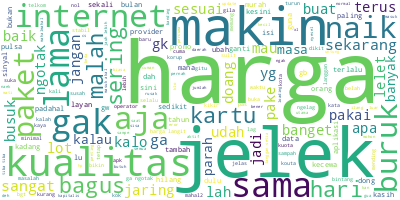

In [41]:
c = 0
print('Kmeans for cluster ' + str(c))
df_c = df[df['Kmeans_label'] == c]
long_string = ','.join(list(df_c['Teks_Bersih'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

Kmeans for cluster 1


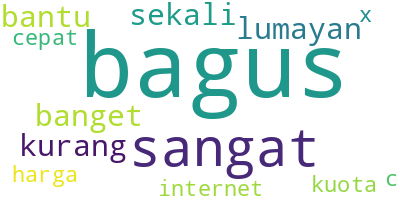

In [42]:
c = 1
print('Kmeans for cluster ' + str(c))
df_c = df[df['Kmeans_label'] == c]
long_string = ','.join(list(df_c['Teks_Bersih'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

Kmeans for cluster 2


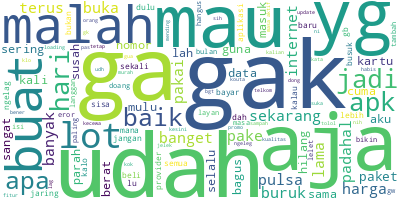

In [43]:
c = 2
print('Kmeans for cluster ' + str(c))
df_c = df[df['Kmeans_label'] == c]
long_string = ','.join(list(df_c['Teks_Bersih'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

Kmeans for cluster 3


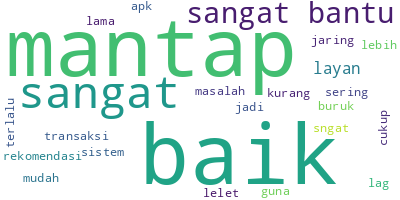

In [44]:
c = 3
print('Kmeans for cluster ' + str(c))
df_c = df[df['Kmeans_label'] == c]
long_string = ','.join(list(df_c['Teks_Bersih'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

**Hubungan cluster dengan Rating** (apakah cluster cenderung berisi review positif / negatif?)

In [45]:
pd.crosstab(df['Kmeans_label'], df['Rating'])

Rating,1,2,3,4,5
Kmeans_label,,,,,
0,231,22,9,6,17
1,3,1,3,7,63
2,990,94,67,44,206
3,8,1,2,9,103


**Analisis K-Means:**

*   cluster 0 - sangat dominan ulasan negatif karena dodiminasi oleh rating 1 (sebanyak 231 ulasan)
*   cluster 1 - sangat dominan ulasan positif karena di dominasi oleh rating 5 (63 ulasan)
*   cluster 2 - mayoritas keluhan/ulasan negatif berat karena memiliki jumlah ulasan terbanyak yg didominasi oleh rating 1 (990 ulasan) dan rating 2 (94 ulasan)
*   cluster 3 - dominan ulasan posotif singkat (isinya ungkapan puas yg singkat dari pelanggan, misalnya kata 'mantap', 'baik', 'puas') dan ini didominasi oleh rating 5 (103 ulasan) dan rating 4 (9 ulasan)





# **Hierarchical Clustering**

**visualisasi dendrogram**

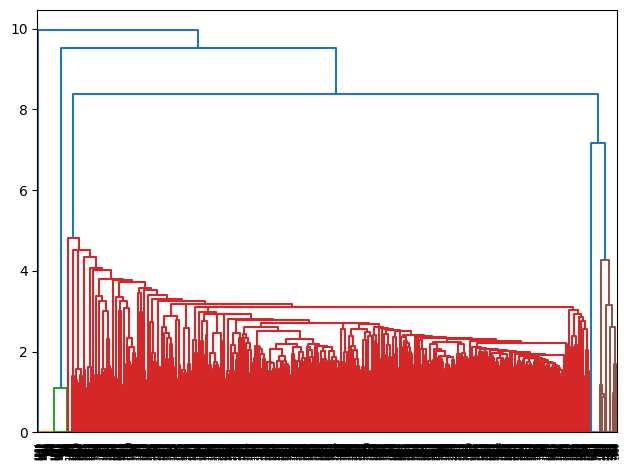

In [46]:
from scipy.cluster.hierarchy import dendrogram, linkage

linkage_data = linkage(df_FE, method='ward', metric='euclidean')
dendrogram(linkage_data)
plt.tight_layout()
plt.show()

Dendrogram di atas isinya ribuan review jadi daun-daunnya numpuk. Supaya lebih kebaca, versi yang dipotong (hanya menampilkan 30 gabungan terakhir):

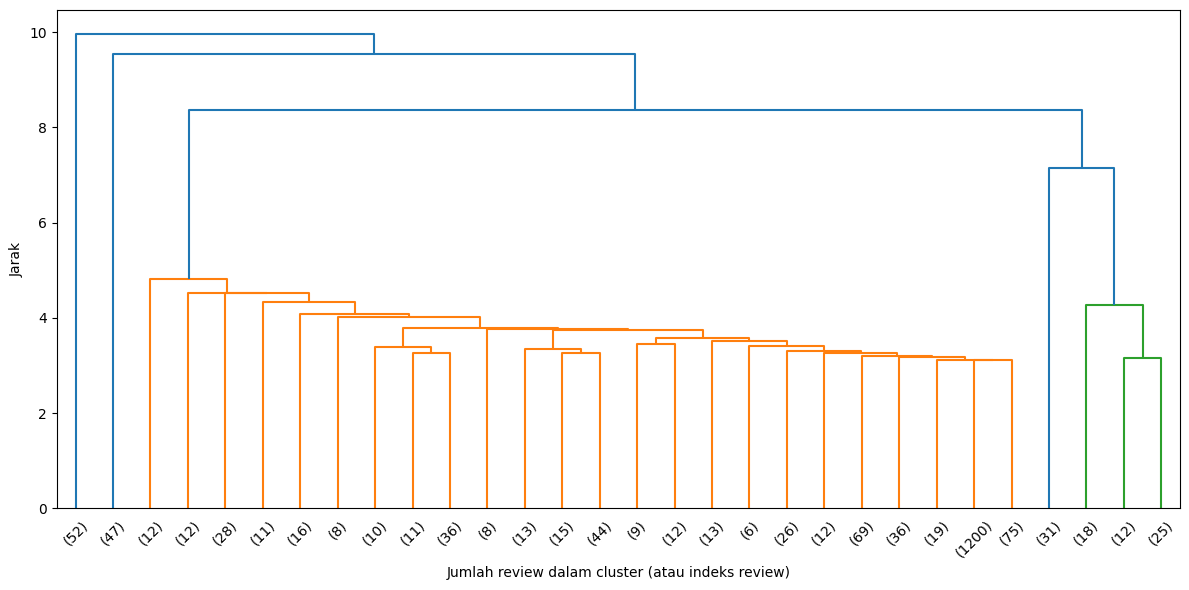

In [47]:
plt.figure(figsize=(12, 6))
dendrogram(linkage_data, truncate_mode='lastp', p=30)
plt.xlabel('Jumlah review dalam cluster (atau indeks review)')
plt.ylabel('Jarak')
plt.tight_layout()
plt.show()

In [48]:
from sklearn.cluster import AgglomerativeClustering

hierarchical_cluster = AgglomerativeClustering(n_clusters=n_clusters, linkage='ward')
labels = hierarchical_cluster.fit(df_FE)

pred_agc = pd.Series(hierarchical_cluster.labels_)
df['Ward_label'] = pred_agc

In [49]:
# jumlah review di tiap cluster
df['Ward_label'].value_counts().sort_index()

,count
Ward_label,
0,86
1,1701
2,47
3,52


**Silhouette Score**

In [50]:
labels = pred_agc
metrics.silhouette_score(df_FE, labels, metric='euclidean')

np.float64(0.056940171606637474)

In [51]:
print("Davies-Bouldin Index (makin kecil makin bagus):", metrics.davies_bouldin_score(df_FE, labels))
print("Calinski-Harabasz Index (makin besar makin bagus):", metrics.calinski_harabasz_score(df_FE, labels))

Davies-Bouldin Index (makin kecil makin bagus): 1.8261759521030874
Calinski-Harabasz Index (makin besar makin bagus): 47.56834873490145


**Word Cloud**

Hierarchical for cluster 0


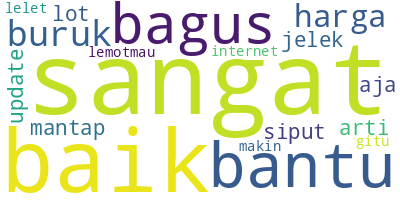

In [52]:
c = 0
print('Hierarchical for cluster ' + str(c))
df_c = df[df['Ward_label'] == c]
long_string = ','.join(list(df_c['Teks_Bersih'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

Hierarchical for cluster 1


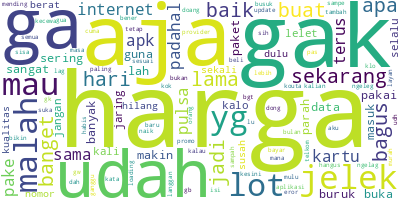

In [53]:
c = 1
print('Hierarchical for cluster ' + str(c))
df_c = df[df['Ward_label'] == c]
long_string = ','.join(list(df_c['Teks_Bersih'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

Hierarchical for cluster 2


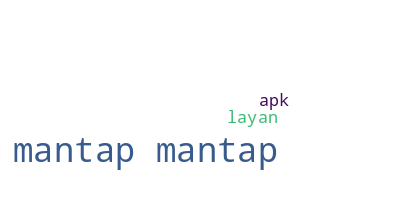

In [54]:
c = 2
print('Hierarchical for cluster ' + str(c))
df_c = df[df['Ward_label'] == c]
long_string = ','.join(list(df_c['Teks_Bersih'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

Hierarchical for cluster 3


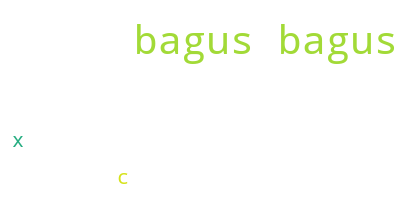

In [55]:
c = 3
print('Hierarchical for cluster ' + str(c))
df_c = df[df['Ward_label'] == c]
long_string = ','.join(list(df_c['Teks_Bersih'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

**Hubungan cluster dengan Rating**

In [56]:
pd.crosstab(df['Ward_label'], df['Rating'])

Rating,1,2,3,4,5
Ward_label,,,,,
0,8,1,3,4,70
1,1222,116,76,52,235
2,2,0,0,5,40
3,0,1,2,5,44


**Analisis Hierarchical:**
*   cluster 0 = sangat dominan dengan ulasan positif karena didominasi oleh rating 5 (70 ulasan) dari total 86 ulasan.
*   cluster 1 = dominan ulasan negatif karena di sini menampung junmlah data terbesar dan sangat didominasi oleh Rating 1 (1.222 ulasan) serta Rating 2 (116 ulasan), meskipun terdapat pula 235 ulasan ber-rating 5
*   cluster 2 = dominan ulasan positif karena di cluster ini didominasi oleh rating 5 (40 ulasan) dan rating 4 (5 ulasan) dari total 47 data
*   cluster 3 = sangat dominan oleh ulasan positif karena hampir seluruh anggotanya merupakan ulasan positif, yaitu rating 5 (44 ulasan) dan rating 4 (5 ulasan).






# **Perbandingan K-Means vs Hierarchical**

In [57]:
hasil = pd.DataFrame({
    'Metode': ['K-Means', 'Hierarchical (Ward)'],
    'Silhouette Score': [
        metrics.silhouette_score(df_FE, df['Kmeans_label']),
        metrics.silhouette_score(df_FE, df['Ward_label'])
    ],
    'Davies-Bouldin': [
        metrics.davies_bouldin_score(df_FE, df['Kmeans_label']),
        metrics.davies_bouldin_score(df_FE, df['Ward_label'])
    ],
    'Calinski-Harabasz': [
        metrics.calinski_harabasz_score(df_FE, df['Kmeans_label']),
        metrics.calinski_harabasz_score(df_FE, df['Ward_label'])
    ]
})
hasil

,Metode,Silhouette Score,Davies-Bouldin,Calinski-Harabasz
0,K-Means,0.04220,5.126285,39.717995
1,Hierarchical (Ward),0.05694,1.826176,47.568349


**Kesimpulan:**

Berdasarkan ketiga metrik evaluasi di atas, algoritma Hierarchical Clustering (Ward) memberikan performa pengelompokan yang lebih unggul secara signifikan dibandingkan K-Means untuk dataset ulasan teks ini.


In [58]:
# simpan hasil clustering
df.to_csv('review_mytelkomsel_clustering.csv', index=False, encoding='utf-8-sig')